# **MÓDULO 39 - Exercicio - Aplicando XGboost**

Nessa atividade vocês usarão uma base já connhecida, a base de propensão a compra de carros.
Já utilizamos essa base antes, nessa atividade, você deve carregar a base, realizar os tratamentos necessários, rodar o XGBoost, encontrar as principais variaveis.
Vamos lá!

In [35]:
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.preprocessing import LabelEncoder

# 1. Carrega a base de dados, verifique os tipos de dados, dados faltantes e drop a coluna ID.


In [2]:
df = pd.read_csv('CARRO_CLIENTES.csv')

In [3]:
df.head()

,User ID,Gender,Age,AnnualSalary,Purchased
0,385,Male,35,20000,0
1,681,Male,40,43500,0
2,353,Male,49,74000,0
3,895,Male,40,107500,1
4,661,Male,25,79000,0


In [4]:
df.isnull().sum()

User ID         0
Gender          0
Age             0
AnnualSalary    0
Purchased       0
dtype: int64

In [5]:
df.dtypes

User ID         int64
Gender            str
Age             int64
AnnualSalary    int64
Purchased       int64
dtype: object

In [6]:
df = df.drop(columns=('User ID'))

In [7]:
df.head()

,Gender,Age,AnnualSalary,Purchased
0,Male,35,20000,0
1,Male,40,43500,0
2,Male,49,74000,0
3,Male,40,107500,1
4,Male,25,79000,0


# 2. Aplique o Label Encoder para a coluna Gender e exclua a coluna categórica.

In [8]:
encoder = LabelEncoder()

In [9]:
df['Gender_encoded'] = encoder.fit_transform(df['Gender'])

In [10]:
df = df.drop(columns=('Gender'))

In [11]:
df.head()

,Age,AnnualSalary,Purchased,Gender_encoded
0,35,20000,0,1
1,40,43500,0,1
2,49,74000,0,1
3,40,107500,1,1
4,25,79000,0,1


# 3. Faça a matriz de correlação e analise as váriaveis que parecem ter maior correlação com a váriavel target.

In [12]:
cm = df.select_dtypes(include=['number']).corr()
cm

,Age,AnnualSalary,Purchased,Gender_encoded
Age,1.000000,0.166042,0.616036,-0.084760
AnnualSalary,0.166042,1.000000,0.364974,-0.063301
Purchased,0.616036,0.364974,1.000000,-0.047211
Gender_encoded,-0.084760,-0.063301,-0.047211,1.000000


As variáveis com maior correlação com a target (`Purchased`) são: `Age` (0.61) e `AnnualSalary` (0.36).

# 4. Faça a separação da base em X e Y e em seguida nas bases de treino e teste.

In [13]:
X = df.drop(columns=('Purchased'))
Y = df['Purchased']

In [14]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# 5. Treino o modelo Xgboost com sua base de treino.
Pesquise alguns hyperparametros na bibllioteca para utilizar, utilize ao menos 2.

In [15]:
modelo = xgb.XGBClassifier()

In [16]:
param_grid = {
    "n_estimators": [200, 300, 400, 600, 800], 
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
    "min_child_weight": [1, 2, 3, 5, 7], 
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "gamma": [0, 0.1, 0.3, 0.5, 1], 
    "reg_alpha": [0, 0.01, 0.1, 0.5, 1], 
    "reg_lambda": [1, 2, 5, 10]
}

[LINK DA DOCUMENTAÇÃO](https://xgboost.readthedocs.io/en/stable/parameter.html)

| Parâmetro | Controla | Aumentar o valor tende a... |
| --- | --- | --- |
| `n_estimators` | Número de árvores | Aumentar a capacidade de aprendizado e o custo computacional |
| `max_depth` | Profundidade das árvores | Aumentar a complexidade |
| `learning_rate` | Contribuição de cada árvore | Acelerar o aprendizado, com risco de ajuste excessivo |
| `min_child_weight` | Restrição às divisões | Tornar o modelo mais conservador |
| `subsample` | Amostragem de linhas | Reduzir a aleatoriedade quando se aproxima de 1 |
| `colsample_bytree` | Amostragem de features | Considerar mais variáveis por árvore |
| `gamma` | Exigência para realizar divisões | Tornar as árvores mais conservadoras |
| `reg_alpha` | Regularização L1 | Aumentar a penalização dos pesos |
| `reg_lambda` | Regularização L2 | Aumentar a penalização dos pesos |

In [17]:
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [18]:
search = RandomizedSearchCV(
    modelo,
    param_distributions=param_grid,
    n_iter=100,
    cv=cross_validation,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

In [19]:
search.fit(X_train, Y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.02, 0.03, ...], 'max_depth': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",100
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here

In [20]:
best_param = search.best_params_
print(f'Melhores Parâmetros: {best_param}')

Melhores Parâmetros: {'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0.5, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 1, 'colsample_bytree': 0.8}


In [21]:
best_modelo = search.best_estimator_
best_modelo.fit(X_train, Y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBR

In [22]:
Y_pred1 = best_modelo.predict(X_train)

In [23]:
report1 = classification_report(Y_train, Y_pred1)
print(f'Relatório de Classificação: \n{report1}')

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       486
           1       0.89      0.92      0.91       314

    accuracy                           0.93       800
   macro avg       0.92      0.93      0.92       800
weighted avg       0.93      0.93      0.93       800



### Avaliação Validação Cruzada:

In [24]:
cv_scores = cross_val_score(
    best_modelo,
    X_train,
    Y_train,
    cv=cross_validation,
    scoring='accuracy',
    n_jobs=-1
)

In [25]:
print(f"Scores cross validation: {cv_scores}")
print(f"Acurácia média: {np.mean(cv_scores):.2f}")
print(f"Desvio padrão: {np.std(cv_scores):.2f}")

Scores cross validation: [0.925  0.9375 0.9    0.875  0.925 ]
Acurácia média: 0.91
Desvio padrão: 0.02


A **validação cruzada**, apresentou uma `accuracy` média de 91% e um desvio padrão (`std`) de 2 pontos percentuais. Os resultados demonstram que o modelo mantém um desempenho relativamente estável entre as diferentes partições dos dados.

# 6. Realize as previsões para a base de teste e traga as probabilidades das previsões.

In [26]:
Ypred2 = best_modelo.predict(X_test)

In [27]:
report2 = classification_report(Y_test, Ypred2)
print(f'Relatório de Classificação: \n{report2}')

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.91      0.95      0.93       112
           1       0.93      0.88      0.90        88

    accuracy                           0.92       200
   macro avg       0.92      0.91      0.91       200
weighted avg       0.92      0.92      0.91       200



### Probabilidades de cada classe:

In [28]:
Y_pred_prob = best_modelo.predict_proba(X_test)
Y_pred_prob

array([[0.8288156 , 0.1711844 ],
       [0.02020317, 0.9797968 ],
       [0.99562794, 0.00437209],
       [0.4687789 , 0.5312211 ],
       [0.11302161, 0.8869784 ],
       [0.14461851, 0.8553815 ],
       [0.05082506, 0.94917494],
       [0.99082553, 0.00917446],
       [0.9678762 , 0.0321238 ],
       [0.9661977 , 0.03380225],
       [0.9130678 , 0.08693217],
       [0.99555767, 0.0044423 ],
       [0.89636964, 0.10363039],
       [0.9864233 , 0.0135767 ],
       [0.09553522, 0.9044648 ],
       [0.23886722, 0.7611328 ],
       [0.54570806, 0.4542919 ],
       [0.0398736 , 0.9601264 ],
       [0.19443303, 0.80556697],
       [0.97811496, 0.02188506],
       [0.9530619 , 0.04693812],
       [0.0575217 , 0.9424783 ],
       [0.1759361 , 0.8240639 ],
       [0.99612224, 0.00387776],
       [0.04306269, 0.9569373 ],
       [0.9130678 , 0.08693217],
       [0.26249665, 0.73750335],
       [0.10263532, 0.8973647 ],
       [0.9530132 , 0.04698681],
       [0.37213373, 0.62786627],
       [0.

# 7. Faça a transformação das probabilidades nas previsões binárias e avalie o desempenho do modelo.

A variável `Purchased` já está codificada como 0 e 1, logo não é preciso utilizar `inverse_transform()` para avaliar o modelo.

**Resultados do Relatório de Classificação:**

- `Accuracy`: o modelo acertou 93% das previsões no treino e 92% no teste. A diferença de apenas 1 ponto percentual sugere uma boa capacidade de generalização.

- `Precision`: os valores próximos de 92%–93% indicam que o modelo apresenta uma boa proporção de previsões corretas entre as classificações positivas que realiza.

- `Recall`: os valores de 91%–93% sugerem que o modelo consegue identificar a maior parte dos exemplos pertencentes às classes.

- `F1-score`: os resultados de 91%–93% indicam um bom equilíbrio entre precisão e recall.

In [31]:
matrix = confusion_matrix(Y_test, Ypred2)
print(f'Matriz de Confusão: \n{matrix}')

Matriz de Confusão: 
[[106   6]
 [ 11  77]]


**Resultados da Matriz de Confusão:**

- 106 exemplos `0` classificados corretamente.

- 6 exemplos `0` classificados incorretamente como `1`.

- 11 exemplos `1` classificados incorretamente como `0`.

- 77 exemplos `1` classificados corretamente.

O modelo apresentou maior dificuldade na classificação da classe `1`.

### ROC-AUC:

In [33]:
roc_auc = roc_auc_score(Y_test, Ypred2)
print(f'AUC: {roc_auc: .2f}')

AUC:  0.91


In [34]:
fpr, tpr, thresholds = roc_curve(Y_test, Ypred2)

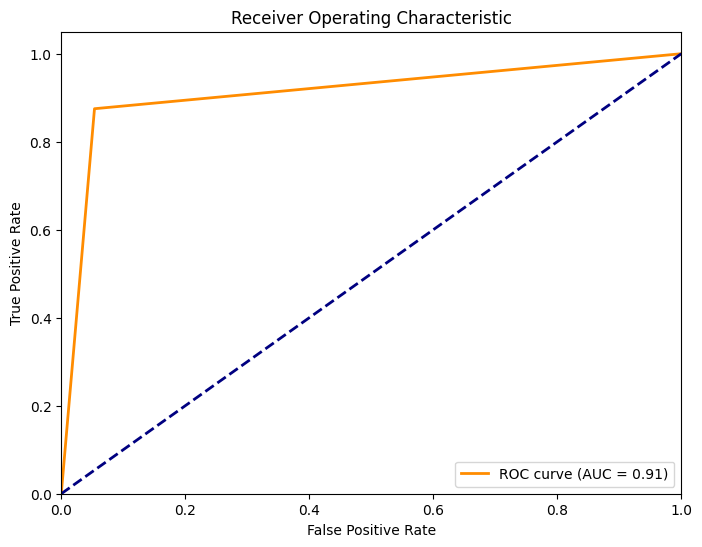

In [38]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

A curva `ROC` apresentou uma área sob a curva (`ROC-AUC`) de 0.91, indicando uma excelente capacidade de distinguir clientes que compraram o carro daqueles que não compraram.

# 8. Traga a lista com a feature importance.
As features mais importantes são as mesmas que indicaram maior correlação na matriz de correlação?

In [32]:
list(zip(X.columns, best_modelo.feature_importances_))

[('Age', np.float32(0.5352667)),
 ('AnnualSalary', np.float32(0.4018351)),
 ('Gender_encoded', np.float32(0.062898204))]

As duas variáveis mais importantes coincidem nas duas análises: `Age` e `AnnualSalary`. Isso indica consistência entre a associação linear observada na **matriz de correlação** e a contribuição das variáveis para as previsões do **XGBoost**. No entanto, as medidas são diferentes: a correlação mede associação linear, enquanto o gain mede a melhoria da função objetivo proporcionada pelas divisões das árvores.